# Stage-1 and stage-2 design choices: measured comparisons

This notebook records the experiments behind the main design choices of the traceability component (C4): which model finds candidate files (stage 1), whether extra signals help, and how the LLM check (stage 2) and the decay check behave. The cells **run the comparisons**; a result is only read from a file when it needs a GPU or the slow LLM server, and each section says which of the two it is.

| # | Topic | Compared | How it is checked here |
|---|---|---|---|
| 3 | Stage-1 embedding model | MiniLM, code-search, UniXcoder, TF-IDF, hybrids (7 datasets) | **re-run** |
| 4 | Fine-tuned CodeBERT as a third signal | TF-IDF + MiniLM with and without CodeBERT (7 datasets) | **re-run** |
| 5 | Cross-encoder reranker | stage 1 alone vs stage 1 + reranker, three shortlist sizes | **re-run** (untrained model); fine-tuned models: stored Colab results |
| 6 | Query expansion with the LLM | with vs without | **recomputed** from the stored LLM answers |
| 7 | Verifier LLM | Llama 3.1 8B, Qwen2.5-coder, Gemma 2 (120 pairs) | **recomputed** from the stored answers; optional re-ask switch |
| 8 | Verification prompt | expert vs evidence prompt | **recomputed** from the stored verdicts; quote check **run** |
| 9 | Decay detection | LLM alone vs LLM + meaning-change check | meaning-change check **re-run**; LLM outcomes recomputed from stored runs |
| 10 | Targets | measured vs required | computed from the sections above |

Everything that is re-run is deterministic (fixed seeds), so a second run gives the same numbers.

## 1. Setup

Finds the project folder. No GPU, Neo4j or LLM server is needed: the embedding models and the cross-encoder are already on this computer and are loaded offline. The cells in sections 3 to 5 take about five minutes in total.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
os.environ.setdefault('HF_HUB_OFFLINE', '1')        # the models are already on this computer: nothing is downloaded
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'agents').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'agents').is_dir():
    raise RuntimeError('Start this notebook from inside the project folder (the one that contains agents/).')
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
RESULTS = ROOT / 'data' / 'results'
def saved(name): return json.loads((RESULTS / name).read_text(encoding='utf-8'))
print('project folder:', ROOT); print('result files found:', len(list(RESULTS.glob('*.json'))))

project folder: /Users/habbglobal/Desktop/J26-SE-327/project
result files found: 27


Plot style and a table printer, shared by all sections.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
GREY, BLUE, GREEN, GOLD, RED, PURPLE, ORANGE = '#9aa5b1', '#4c78a8', '#2f6f4e', '#c9a227', '#d1495b', '#9b5de5', '#e07a1f'

def show_table(rows, columns, width=44, fmt='{:10.3f}'):
    """Print {name: {metric: value}} as an aligned text table."""
    print(f"{'':{width}s}" + ''.join(f'{c:>10s}' for c in columns))
    for name, r in rows.items():
        print(f'{name:{width}s}' + ''.join(fmt.format(r[c]) for c in columns))

## 2. Method used in every comparison

* **Data:** seven public datasets with expert-labelled requirement-to-code links (iTrust, eTour, SMOS, eANCI, LibEST, CM-1, EBT). Every option sees the same requirements, the same files and the same answer key.
* **Pipeline code:** the project's own functions (`retrieval.py`, `preprocess.py`, `semdiff.py`, `decay_injection.py`), so the only thing that changes between options is the option itself.
* **Metrics:** *recall@k* = the share of all true links that are found in the top k files of their requirement; *hits@k* = the number of true links found in the top k of one requirement.
* **Is a difference real?** Differences are tested with a **paired bootstrap** over requirements (2000 resamples, seed 13): the mean difference per requirement with a 95% interval; `*` marks an interval that excludes 0. Proportions (precision, recall) get 95% Wilson intervals.
* **Sizes differ a lot between datasets:** LibEST has 14 code files, iTrust 392; SMOS and eANCI have about 15 true links per requirement, so recall@10 cannot exceed about 0.65 there. Compare methods **within** a dataset; the average over datasets only summarises.

Helpers: loading a dataset, recall, hits per requirement, the paired bootstrap, and a size table of the seven datasets.

In [3]:
from agents.traceability_agent.preprocess import retrieval_text, llm_text
from agents.traceability_agent.retrieval import embedding_matrix, tfidf_matrix, zscore_fuse, chunk_words
from agents.traceability_agent.config import CHUNK_WORDS
from agents.traceability_agent.decay_injection import wilson
from shared.embeddings.embedder import Embedder
from shared.schemas.traceability import Artifact

DATASETS = ['itrust', 'etour', 'smos', 'eanci', 'libest', 'cm1', 'ebt']
KS = (5, 10, 20)

def load(name):
    """Requirements, code files and the expert answer key {requirement index: {code indices}} of one dataset."""
    P = ROOT / 'data' / 'processed' / name
    arts = [Artifact(**a) for a in json.loads((P / 'artifacts.json').read_text(encoding='utf-8'))]
    traces = json.loads((P / 'traces.json').read_text(encoding='utf-8'))
    reqs, code_ = [a for a in arts if a.type == 'requirement'], [a for a in arts if a.type != 'requirement']
    ri, ci = {a.id: i for i, a in enumerate(reqs)}, {a.id: i for i, a in enumerate(code_)}
    gold = {}
    for t in traces:
        if t['source_id'] in ri and t['target_id'] in ci: gold.setdefault(ri[t['source_id']], set()).add(ci[t['target_id']])
    return reqs, code_, gold

def hits_per_req(matrix, gold, k):
    """True links found in the top k of each requirement that has at least one true link."""
    return np.array([len(truth & set(np.argsort(-matrix[i])[:k].tolist())) for i, truth in gold.items()], dtype=float)

def recall(matrix, gold, k):
    """Share of all true links that are found in the top k of their requirement."""
    return hits_per_req(matrix, gold, k).sum() / sum(len(t) for t in gold.values())

def paired_bootstrap(a, b, n=2000, seed=13):
    """Mean of (b - a) over requirements with a 95% bootstrap interval. a and b hold one value per requirement, same order."""
    d = np.asarray(b, dtype=float) - np.asarray(a, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    lo, hi = np.percentile(means, [2.5, 97.5])
    return float(d.mean()), float(lo), float(hi)

def fmt_ci(m, lo, hi, sign=True):
    star = ' *' if (lo > 0 or hi < 0) else ''
    return (f'{m:+.3f}' if sign else f'{m:.3f}') + f' [{lo:+.3f}, {hi:+.3f}]{star}'

DATA = {ds: load(ds) for ds in DATASETS}
print('dataset   requirements  code files  requirements with links  true links')
for ds, (r, c, g) in DATA.items():
    print(f'{ds:9s} {len(r):12d} {len(c):11d} {len(g):24d} {sum(len(t) for t in g.values()):11d}')

dataset   requirements  code files  requirements with links  true links
itrust             131         392                      111         399
etour               58         116                       57         308
smos                67         100                       67        1044
eanci               39          55                       39         567
libest              52          14                       47         204
cm1                 22          53                       19          45
ebt                 41          50                       33          98


## 3. Stage-1 embedding model

**Objective.** Stage 1 turns requirements and code into vectors and shortlists the closest files. Is a general sentence model (MiniLM) enough, or does a code-specific model do better?

**Options** (each used as published, none trained here)
* **MiniLM** (`all-MiniLM-L6-v2`): general-purpose sentence model.
* **code-search** (`st-codesearch-distilroberta-base`): trained to match natural-language queries to code.
* **UniXcoder** (`unixcoder-base`): trained on code and comments; used with plain mean pooling.
* **TF-IDF:** word counting, no model.
* **hybrid** = TF-IDF + the embedding, fused by z-score (what the pipeline uses).

The next cell scores all of them on all seven datasets (about two minutes).

In [4]:
MODELS = {'MiniLM': 'all-MiniLM-L6-v2', 'code-search': 'flax-sentence-embeddings/st-codesearch-distilroberta-base', 'UniXcoder': 'microsoft/unixcoder-base'}
embedders = {name: Embedder(path) for name, path in MODELS.items()}
MAT = {ds: {} for ds in DATASETS}          # score matrices kept for the later sections
live = {}
t0 = time.time()
for ds in DATASETS:
    reqs, code_, gold = DATA[ds]
    tf = tfidf_matrix(reqs, code_, retrieval_text, CHUNK_WORDS)
    MAT[ds]['TF-IDF'] = tf
    live[ds] = {'TF-IDF': {k: recall(tf, gold, k) for k in KS}}
    for name, emb in embedders.items():
        m = embedding_matrix(reqs, code_, emb, retrieval_text, CHUNK_WORDS)
        MAT[ds][name] = m
        live[ds][name + ' (embedding)'] = {k: recall(m, gold, k) for k in KS}
        live[ds][name + ' + TF-IDF'] = {k: recall(zscore_fuse([tf, m]), gold, k) for k in KS}
    print(f'{ds:7s} done ({time.time() - t0:.0f} s)')

No sentence-transformers model found with name microsoft/unixcoder-base. Creating a new one with mean pooling.


itrust  done (40 s)


etour   done (59 s)


smos    done (70 s)


eanci   done (80 s)


libest  done (99 s)


cm1     done (101 s)


ebt     done (103 s)


### Reproducibility check against the stored result

Compares each number of this run with `stage1_embeddings.json` and reports the largest difference.

In [5]:
ref = saved('stage1_embeddings.json')
worst = 0.0; checked = 0
for ds in ref:                                              # the stored file has the six datasets it was made for
    for name in MODELS:
        for k in KS:
            a, b = live[ds][name + ' + TF-IDF'][k], ref[ds][name]['hybrid'][str(k)]
            worst = max(worst, abs(a - b)); checked += 1
print(f'{checked} numbers compared; largest difference between this run and the stored result: {worst:.3f}')
print('REPRODUCED: this run gives the same numbers as the stored results.' if worst < 0.01 else 'NOT identical: the data, the pipeline or the models changed since the stored run.')

63 numbers compared; largest difference between this run and the stored result: 0.000
REPRODUCED: this run gives the same numbers as the stored results.


### Results

Recall@10 of the hybrids per dataset, then the average over the seven datasets (each dataset counts once).

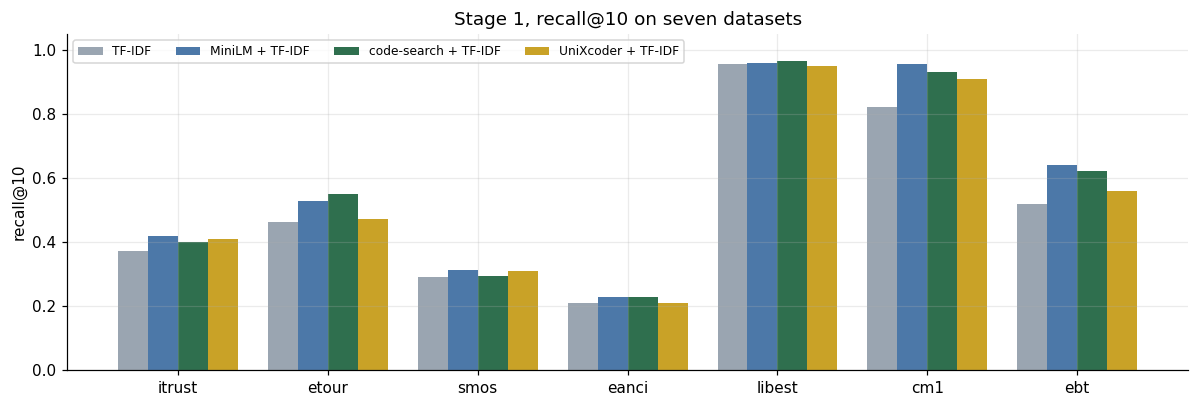

In [6]:
names = ['TF-IDF', 'MiniLM + TF-IDF', 'code-search + TF-IDF', 'UniXcoder + TF-IDF']
x = np.arange(len(DATASETS)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 3.8))
for j, n in enumerate(names):
    ax.bar(x + (j - 1.5) * w, [live[d][n][10] for d in DATASETS], w, label=n, color=[GREY, BLUE, GREEN, GOLD][j])
ax.set_xticks(x); ax.set_xticklabels(DATASETS); ax.set_ylabel('recall@10'); ax.set_ylim(0, 1.05); ax.legend(fontsize=8, ncol=4)
ax.set_title('Stage 1, recall@10 on seven datasets'); plt.tight_layout(); plt.show()

In [7]:
avg = {n: {k: float(np.mean([live[d][n][k] for d in DATASETS])) for k in KS} for n in live[DATASETS[0]]}
print(f"{'method':32s}" + ''.join(f'  R@{k:<3d}' for k in KS))
for n, r in sorted(avg.items(), key=lambda kv: -kv[1][10]):
    print(f'{n:32s}' + ''.join(f'  {r[k]:.3f}' for k in KS))
wins = {n: sum(live[d][n][10] == max(live[d][m][10] for m in live[d]) for d in DATASETS) for n in ('MiniLM + TF-IDF', 'code-search + TF-IDF', 'UniXcoder + TF-IDF')}
print('\ndatasets where each hybrid has the best recall@10:', wins)

method                            R@5    R@10   R@20 
MiniLM + TF-IDF                   0.381  0.578  0.710
code-search + TF-IDF              0.375  0.571  0.706
MiniLM (embedding)                0.373  0.554  0.674
UniXcoder + TF-IDF                0.368  0.547  0.696
code-search (embedding)           0.339  0.534  0.672
TF-IDF                            0.343  0.520  0.689
UniXcoder (embedding)             0.301  0.460  0.621

datasets where each hybrid has the best recall@10: {'MiniLM + TF-IDF': np.int64(4), 'code-search + TF-IDF': np.int64(1), 'UniXcoder + TF-IDF': np.int64(0)}


### Is the difference between the methods real?

Pooled over the 373 requirements that have at least one true link, counted in true links found in the top 10.

In [8]:
def pooled_hits(matrices_by_ds, k=10):
    return np.concatenate([hits_per_req(matrices_by_ds[ds], DATA[ds][2], k) for ds in DATASETS])

fused = {name: {ds: zscore_fuse([MAT[ds]['TF-IDF'], MAT[ds][name]]) for ds in DATASETS} for name in MODELS}
base = pooled_hits(fused['MiniLM'])
rows = [('TF-IDF alone', pooled_hits({ds: MAT[ds]['TF-IDF'] for ds in DATASETS})),
        ('MiniLM alone', pooled_hits({ds: MAT[ds]['MiniLM'] for ds in DATASETS})),
        ('code-search + TF-IDF', pooled_hits(fused['code-search'])),
        ('UniXcoder + TF-IDF', pooled_hits(fused['UniXcoder']))]
print(f'requirements pooled over the seven datasets: {len(base)}')
print('extra true links per requirement in the top 10, MiniLM + TF-IDF minus the method named (95% bootstrap interval, * = interval excludes 0)')
for name, other in rows:
    print(f'  vs {name:24s} {fmt_ci(*paired_bootstrap(other, base))}')

requirements pooled over the seven datasets: 373
extra true links per requirement in the top 10, MiniLM + TF-IDF minus the method named (95% bootstrap interval, * = interval excludes 0)
  vs TF-IDF alone             +0.239 [+0.161, +0.324] *
  vs MiniLM alone             +0.247 [+0.145, +0.357] *
  vs code-search + TF-IDF     +0.054 [-0.016, +0.126]
  vs UniXcoder + TF-IDF       +0.115 [+0.032, +0.198] *


**Observations**
* The embedding models used alone are not better than word counting: TF-IDF 0.520, MiniLM 0.554, code-search 0.534, UniXcoder 0.460 (average recall@10).
* Fusing with TF-IDF helps every model. MiniLM + TF-IDF finds 0.24 more true links per requirement in the top 10 than TF-IDF alone and 0.25 more than MiniLM alone (both intervals exclude 0).
* MiniLM + TF-IDF has the best average (0.578) and is best on four of seven datasets, but its lead over code-search + TF-IDF (+0.05, interval includes 0) is **not distinguishable from chance**. It is clearly ahead of UniXcoder + TF-IDF.

**Conclusion.** Stage 1 stays TF-IDF + MiniLM. The code-specific models did not beat the general one; code-search ties it, so MiniLM is kept as the smaller model (model size and speed were not measured here).

**Limits.** UniXcoder was only used with mean pooling; no model was fine-tuned in this comparison; the datasets differ in language and size.

## 4. Fine-tuned CodeBERT as a third signal

**Objective.** A CodeBERT was fine-tuned on LLM-written requirement/code pairs (`models/c4-codebert`) and can be fused with TF-IDF and MiniLM as a third signal. Does that improve stage 1 on real projects?

**Procedure.** The model is applied to all seven datasets with the pipeline's own `embedding_matrix`; every combination of the three signals is scored. The model was not trained on any of these datasets.

In [9]:
cb = Embedder('c4-codebert')        # fine-tuned CodeBERT stored in models/ (trained on LLM-written pairs, not on these datasets)
t0 = time.time()
for ds in DATASETS:
    reqs, code_, gold = DATA[ds]
    MAT[ds]['CodeBERT'] = embedding_matrix(reqs, code_, cb, retrieval_text, CHUNK_WORDS)
    print(f'{ds:7s} done ({time.time() - t0:.0f} s)')

COMBOS = {'TF-IDF': ['TF-IDF'], 'MiniLM': ['MiniLM'], 'CodeBERT': ['CodeBERT'],
          'TF-IDF + MiniLM (before)': ['TF-IDF', 'MiniLM'], 'TF-IDF + CodeBERT': ['TF-IDF', 'CodeBERT'], 'MiniLM + CodeBERT': ['MiniLM', 'CodeBERT'],
          'TF-IDF + MiniLM + CodeBERT (after)': ['TF-IDF', 'MiniLM', 'CodeBERT']}
def combo_matrix(ds, parts): return MAT[ds][parts[0]] if len(parts) == 1 else zscore_fuse([MAT[ds][p] for p in parts])
cb_res = {ds: {n: {k: recall(combo_matrix(ds, p), DATA[ds][2], k) for k in KS} for n, p in COMBOS.items()} for ds in DATASETS}

No sentence-transformers model found with name /Users/habbglobal/Desktop/J26-SE-327/project/models/c4-codebert. Creating a new one with mean pooling.


itrust  done (22 s)


etour   done (33 s)


smos    done (40 s)


eanci   done (45 s)


libest  done (55 s)


cm1     done (56 s)


ebt     done (57 s)


Check against the stored result (`stage1_codebert_real_projects.json`).

In [10]:
ref = saved('stage1_codebert_real_projects.json')['projects']
worst = max(abs(cb_res[ds][n][10] - ref[ds]['table'][n]['recall@10']) for ds in ref for n in COMBOS)
print(f'largest difference between this run and the stored result (recall@10, {len(ref) * len(COMBOS)} numbers): {worst:.3f}')
print('REPRODUCED' if worst < 0.01 else 'NOT identical: the data, the pipeline or the models changed since the stored run.')

largest difference between this run and the stored result (recall@10, 49 numbers): 0.000
REPRODUCED


In [11]:
mean10 = {n: float(np.mean([cb_res[ds][n][10] for ds in DATASETS])) for n in COMBOS}
print('recall@10 per dataset')
show_table({n: {ds: cb_res[ds][n][10] for ds in DATASETS} | {'mean': mean10[n]} for n in COMBOS}, DATASETS + ['mean'], width=38)

before = {ds: combo_matrix(ds, COMBOS['TF-IDF + MiniLM (before)']) for ds in DATASETS}
after = {ds: combo_matrix(ds, COMBOS['TF-IDF + MiniLM + CodeBERT (after)']) for ds in DATASETS}
print('\nextra true links per requirement in the top 10 when CodeBERT is added (95% bootstrap interval, * = interval excludes 0)')
for ds in DATASETS:
    print(f'  {ds:7s} {fmt_ci(*paired_bootstrap(hits_per_req(before[ds], DATA[ds][2], 10), hits_per_req(after[ds], DATA[ds][2], 10)))}')
print(f'  {"pooled":7s} {fmt_ci(*paired_bootstrap(pooled_hits(before), pooled_hits(after)))}')
nomini = {ds: combo_matrix(ds, COMBOS['TF-IDF + CodeBERT']) for ds in DATASETS}
print('\nextra true links per requirement in the top 10 when MiniLM is replaced by CodeBERT (TF-IDF + CodeBERT minus TF-IDF + MiniLM)')
print(f'  {"pooled":7s} {fmt_ci(*paired_bootstrap(pooled_hits(before), pooled_hits(nomini)))}')

recall@10 per dataset
                                          itrust     etour      smos     eanci    libest       cm1       ebt      mean
TF-IDF                                     0.373     0.464     0.291     0.212     0.956     0.822     0.520     0.520
MiniLM                                     0.333     0.510     0.259     0.236     0.971     0.933     0.633     0.554
CodeBERT                                   0.226     0.312     0.177     0.233     0.819     0.822     0.429     0.431
TF-IDF + MiniLM (before)                   0.419     0.529     0.313     0.228     0.961     0.956     0.643     0.578
TF-IDF + CodeBERT                          0.401     0.506     0.247     0.206     0.873     0.911     0.592     0.534
MiniLM + CodeBERT                          0.346     0.455     0.239     0.240     0.877     0.956     0.582     0.528
TF-IDF + MiniLM + CodeBERT (after)         0.419     0.529     0.285     0.233     0.941     0.978     0.653     0.577

extra true links per requ

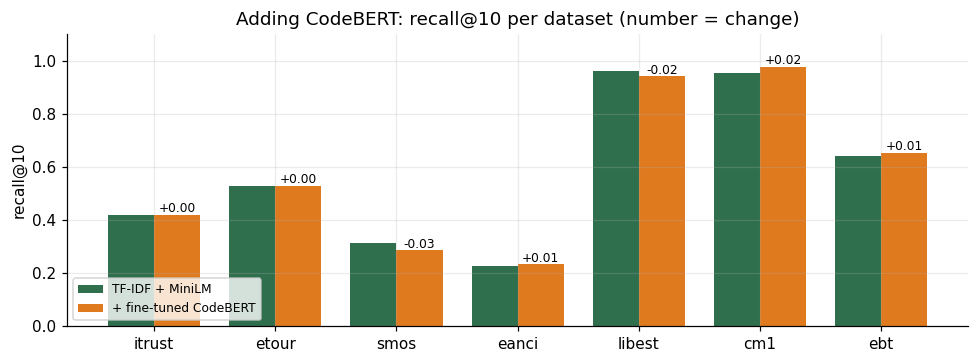

In [12]:
b = [cb_res[ds]['TF-IDF + MiniLM (before)'][10] for ds in DATASETS]; a = [cb_res[ds]['TF-IDF + MiniLM + CodeBERT (after)'][10] for ds in DATASETS]
x = np.arange(len(DATASETS)); w = 0.38; fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x - w / 2, b, w, color=GREEN, label='TF-IDF + MiniLM'); ax.bar(x + w / 2, a, w, color=ORANGE, label='+ fine-tuned CodeBERT')
for i, (u, v) in enumerate(zip(b, a)): ax.text(i + w / 2, v + .01, f'{v - u:+.2f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(DATASETS); ax.set_ylim(0, 1.1); ax.set_ylabel('recall@10'); ax.legend(fontsize=8, loc='lower left'); ax.set_title('Adding CodeBERT: recall@10 per dataset (number = change)'); plt.tight_layout(); plt.show()

**Observations**
* **Alone**, CodeBERT is the weakest signal of all (average recall@10 0.431; MiniLM 0.554, TF-IDF 0.520, UniXcoder 0.460).
* The *average over datasets* does not change when CodeBERT is added (0.578 to 0.577). Counted **per requirement** the picture is slightly worse: pooled, CodeBERT costs 0.075 true links per requirement in the top 10 (interval excludes 0). The loss comes mostly from SMOS (-0.43, the dataset with about 15 true links per requirement, which weighs heavily in absolute links) and LibEST (-0.09); CM-1 is up by 0.05 with the interval touching 0; the other four are indistinguishable from 0.
* Replacing MiniLM by CodeBERT (TF-IDF + CodeBERT) loses 0.32 true links per requirement: **MiniLM is needed, CodeBERT is not**.

**Conclusion.** No evidence that the fine-tuned CodeBERT improves stage 1, and some evidence of a small loss. The likely reason is the training data: LLM-written pairs do not look like real requirements and real files. Training on real labelled links (`codebert_cross_validation.ipynb`, leave-one-project-out) is the untested next step.

**Note.** `.env.example` still enables this model by default (`EXTRA_EMBEDDING_MODEL_NAMES=c4-codebert`); see the open items at the end.

## 5. Cross-encoder reranker after stage 1

**Objective.** A cross-encoder reads the requirement and the code *together* (slower, usually more accurate). Does re-ordering the stage-1 shortlist with one help?

**Procedure** (run here with the untrained `cross-encoder/ms-marco-MiniLM-L-6-v2`)
* Shortlist = the top N files of the stage-1 hybrid. Each pair is the requirement (cut to 160 tokens) and the two 80-word chunks of the file that look most like it.
* Fusion: `z(stage-1 score) + w * z(cross-encoder score)`, z-scored over the shortlist; w = 0.5 and 1.0.
* The fusion weight was first chosen on LibEST, CM-1 and EBT, so the **other four datasets are an independent check**. The shortlist sizes 10, 20 and 50 show how much the shortlist limits the reranker: a true link outside the shortlist can never be recovered.
* The fine-tuned cross-encoders were trained on Colab and are only read from `reranker.json` (the training code is archived).

In [13]:
from sentence_transformers import CrossEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
CE_NAME = 'cross-encoder/ms-marco-MiniLM-L-6-v2'            # used as published, not trained here
ce = CrossEncoder(CE_NAME, max_length=512)
POOL = 50                                                    # the largest shortlist tried; smaller shortlists are slices of it
HELD_OUT = ['libest', 'cm1', 'ebt']                          # the datasets on which the fusion weight was first chosen
OTHERS = [d for d in DATASETS if d not in HELD_OUT]

def clip_tokens(text, n):
    ids = ce.tokenizer(text, add_special_tokens=False)['input_ids'][:n]
    return ce.tokenizer.decode(ids)

def pair_for(req, code_art):
    """Requirement (160 tokens) with the two 80-word chunks of the file that look most like it."""
    chunks = chunk_words(retrieval_text(code_art), 80)
    if len(chunks) > 2:
        m = TfidfVectorizer(lowercase=True, stop_words='english').fit_transform([retrieval_text(req)] + chunks)
        sims = (m[0] @ m[1:].T).toarray().ravel()
        chunks = [chunks[j] for j in sorted(np.argsort(-sims)[:2])]
    return clip_tokens(retrieval_text(req), 160), ' ... '.join(chunks)

SCORED = {}                                                  # ds -> {requirement index: (pool indices, stage-1 scores, cross-encoder scores)}
t0 = time.time()
for ds in DATASETS:
    reqs, code_, gold = DATA[ds]
    stage1 = zscore_fuse([MAT[ds]['TF-IDF'], MAT[ds]['MiniLM']])
    SCORED[ds] = {}
    for i in gold:
        pool = np.argsort(-stage1[i])[:POOL]
        scores = ce.predict([pair_for(reqs[i], code_[j]) for j in pool], batch_size=32, show_progress_bar=False)
        SCORED[ds][i] = (pool, stage1[i][pool], np.asarray(scores, dtype=float))
    print(f'{ds:7s} done ({time.time() - t0:.0f} s)')

itrust  done (35 s)


etour   done (57 s)


smos    done (79 s)


Token indices sequence length is longer than the specified maximum sequence length for this model (2380 > 512). Running this sequence through the model will result in indexing errors


eanci   done (97 s)


libest  done (104 s)


cm1     done (110 s)


ebt     done (117 s)


In [14]:
def z(x): return (x - x.mean()) / (x.std() + 1e-9)

def per_requirement(ds, pool_size, w):
    """Per requirement: (hits@3, hits@5, reciprocal rank) for stage 1 alone and for stage 1 fused with the cross-encoder."""
    gold = DATA[ds][2]; out = []
    for i, (pool, s1, cs) in SCORED[ds].items():
        pool, s1, cs = pool[:pool_size], s1[:pool_size], cs[:pool_size]
        truth = gold[i]; row = []
        for order in (np.arange(len(pool)), np.argsort(-(z(s1) + w * z(cs)), kind='stable')):
            ranked = [pool[j] in truth for j in order]
            first = next((r + 1 for r, hit in enumerate(ranked) if hit), None)
            row += [sum(ranked[:3]), sum(ranked[:5]), 1 / first if first else 0.0]
        out.append(row)
    return np.array(out, dtype=float)             # columns: s1 h3, s1 h5, s1 rr, fused h3, fused h5, fused rr

def gain_table(datasets, pool_size, w):
    arr = np.vstack([per_requirement(ds, pool_size, w) for ds in datasets])
    return {name: paired_bootstrap(arr[:, a], arr[:, b]) for name, (a, b) in {'hits@3': (0, 3), 'hits@5': (1, 4), 'MRR': (2, 5)}.items()}, len(arr)

for title, group in (('datasets where w was first chosen (LibEST, CM-1, EBT)', HELD_OUT), ('the other four datasets (iTrust, eTour, SMOS, eANCI)', OTHERS)):
    print(title)
    for w in (0.5, 1.0):
        g, n = gain_table(group, 20, w)
        print(f'  shortlist 20, w={w}: ' + '   '.join(f'{k} {fmt_ci(*v)}' for k, v in g.items()) + f'   ({n} requirements)')
    print()
st = saved('reranker.json')['heldout_retrieval_level']['untrained_minilm_vs_stage1_all']
print('stored result (Colab, same cross-encoder, LibEST + CM-1 + EBT, shortlist 20):'); [print(f'  {k:12s} {v}') for k, v in st.items()]

datasets where w was first chosen (LibEST, CM-1, EBT)
  shortlist 20, w=0.5: hits@3 +0.081 [-0.020, +0.182]   hits@5 +0.172 [+0.071, +0.273] *   MRR +0.041 [+0.005, +0.080] *   (99 requirements)
  shortlist 20, w=1.0: hits@3 +0.101 [-0.020, +0.222]   hits@5 +0.162 [+0.040, +0.293] *   MRR +0.042 [-0.011, +0.093]   (99 requirements)

the other four datasets (iTrust, eTour, SMOS, eANCI)
  shortlist 20, w=0.5: hits@3 +0.015 [-0.040, +0.069]   hits@5 -0.015 [-0.088, +0.055]   MRR -0.014 [-0.035, +0.006]   (274 requirements)
  shortlist 20, w=1.0: hits@3 -0.044 [-0.113, +0.026]   hits@5 -0.007 [-0.095, +0.084]   MRR -0.017 [-0.044, +0.010]   (274 requirements)

stored result (Colab, same cross-encoder, LibEST + CM-1 + EBT, shortlist 20):
  hits@5_w0.5  +0.115 [+0.026,+0.209]
  hits@5_w1    +0.088 [-0.017,+0.200]
  MRR_w0.5     +0.015 [-0.021,+0.053]
  hits@3_w0.5  +0.009 [-0.070,+0.087]


[None, None, None, None]

### Shortlist size

In [15]:
print('shortlist size: how much of the answer key the shortlist can contain, and the hits@5 gain (w = 0.5) over all seven datasets')
print(f"{'shortlist':>10s}  {'share of true links inside it':>30s}   hits@5 gain")
sizes = (10, 20, 50); rows = []
for n in sizes:
    inside = sum(len(set(SCORED[ds][i][0][:n].tolist()) & DATA[ds][2][i]) for ds in DATASETS for i in SCORED[ds])
    total = sum(len(t) for ds in DATASETS for t in DATA[ds][2].values())
    g, _ = gain_table(DATASETS, n, 0.5)
    rows.append((n, inside / total, g['hits@5']))
    print(f'{n:10d}  {inside / total:30.3f}   {fmt_ci(*g["hits@5"])}')

shortlist size: how much of the answer key the shortlist can contain, and the hits@5 gain (w = 0.5) over all seven datasets
 shortlist   share of true links inside it   hits@5 gain
        10                           0.408   +0.021 [-0.029, +0.075]
        20                           0.553   +0.035 [-0.021, +0.094]


        50                           0.814   +0.056 [-0.008, +0.121]


### Fine-tuned cross-encoders (stored Colab results, not re-run)

In [16]:
rr = saved('reranker.json')['heldout_retrieval_level']
print('data:', rr['datasets'])
for key, label in (('finetuned_minilm_vs_stage1_all', 'fine-tuned MiniLM cross-encoder (trained in Colab)'),):
    print(f'\n{label}'); [print(f'  {m:14s} {v}') for m, v in rr[key].items()]
print('\nfine-tuned CodeBERT cross-encoder (trained in Colab):', rr['codebert_finetuned'])
print('\ncaveats stored with the result:'); [print(' -', c) for c in rr['caveats']]

data: LibEST, CM-1, EBT (115 requirements; never used in training)

fine-tuned MiniLM cross-encoder (trained in Colab)
  hits@5_w0.5    +0.157 [+0.070,+0.252]
  hits@5_w1      +0.138 [+0.017,+0.261]
  MRR_w0.5       +0.026 [-0.004,+0.058]
  hits@3_w0.5    +0.035 [-0.052,+0.122]

fine-tuned CodeBERT cross-encoder (trained in Colab): worse than stage 1 alone (CM-1 MRR 0.211 vs 0.876); fused results inconsistent; not used

caveats stored with the result:
 - weights chosen after seeing test results
 - 115 requirements only; LibEST has 14 code files
 - fine-tune benefit over untrained model not demonstrated


[None, None, None]

**Observations**
* On the three datasets where w was chosen the reranker adds true links to the top 5 (hits@5 +0.17, interval excludes 0) and improves MRR slightly; hits@3 is not distinguishable from 0. The stored Colab run of the same model gives the same direction (+0.115).
* On the **other four datasets there is no gain** (hits@5 -0.015, interval -0.09 to +0.06; MRR -0.014). The gain does not carry over from the datasets on which the weight was chosen.
* Over all seven datasets the hits@5 gain is +0.02, +0.04 and +0.06 for shortlists of 10, 20 and 50, none distinguishable from 0. A shortlist of 20 contains only 55% of the true links (10: 41%, 50: 81%), which caps what any reranker can do.
* Fine-tuning did not show a benefit over the untrained model (overlapping intervals), and the fine-tuned CodeBERT cross-encoder was worse than stage 1 alone.

**Conclusion.** The reranker is not part of the pipeline. A larger shortlist moves recall more than reordering the small one, at the price of more LLM calls.

**Limits.** The weights were chosen after seeing the test results (w = 0.5 and 1.0 are both reported); the pair text here is built from the best two chunks by TF-IDF, which can differ slightly from the Colab run.

## 6. Query expansion with the LLM

**Objective.** Let the LLM write likely class, method and file names for each requirement and append them to the query before stage 1. Does recall go up?

**Procedure.** Llama 3.1 8B was asked once per requirement (the 20 iTrust requirements with at least one true link, 68 true links); its stored answers are appended to the requirement and stage 1 is **re-run here** with and without them. The same cell checks how many of the suggested names occur in the code at all.

In [17]:
qe_saved = saved('query_expansion_itrust.json')
answers = qe_saved['answers']
reqs, code_, gold = DATA['itrust']
ri = {a.id: i for i, a in enumerate(reqs)}
selected = [r for r in reqs if r.id in answers and ri[r.id] in gold]
print(f"{len(selected)} iTrust requirements with at least one true link, {sum(len(gold[ri[r.id]]) for r in selected)} true links; LLM answers stored from {qe_saved['model']}")

def stage1_recall(sources):
    tf = tfidf_matrix(sources, code_, retrieval_text, CHUNK_WORDS)
    em = embedding_matrix(sources, code_, embedders['MiniLM'], retrieval_text, CHUNK_WORDS)
    M = zscore_fuse([tf, em]); out = {}
    for k in KS:
        hit = tot = 0
        for row, r in enumerate(selected):
            truth = gold[ri[r.id]]; hit += len(truth & set(np.argsort(-M[row])[:k].tolist())); tot += len(truth)
        out[k] = hit / tot
    return out

plain = stage1_recall(selected)
expanded = stage1_recall([r.model_copy(update={'text': r.text + ' ' + ' '.join(answers[r.id]['terms'])}) for r in selected])
print(f"\n{'':10s}" + ''.join(f'  top-{k:<3d}' for k in KS))
print(f"{'plain':10s}" + ''.join(f'  {plain[k]:.3f} ' for k in KS)); print(f"{'expanded':10s}" + ''.join(f'  {expanded[k]:.3f} ' for k in KS))

code_text = ' '.join(a.text for a in code_).lower()
terms = [t for r in selected for t in answers[r.id]['terms']]
present = sum(t.lower() in code_text for t in terms)
print(f'\nsuggested names that occur anywhere in the iTrust code: {present} of {len(terms)} ({present / len(terms):.0%})')
print('example answers:'); [print(f"  {r.id}: {', '.join(answers[r.id]['terms'][:5])}") for r in selected[:3]]

20 iTrust requirements with at least one true link, 68 true links; LLM answers stored from llama3.1-8k



            top-5    top-10   top-20 
plain       0.338   0.441   0.544 
expanded    0.338   0.441   0.529 

suggested names that occur anywhere in the iTrust code: 67 of 240 (28%)
example answers:
  UC10E1: MedicalIdentificationService, validateMedicalId, tryAgain, MedicalIdentificationValidator, invalidIdPrompt
  UC10E2: PatientDAO, confirmPatient, selectPatient, PatientService, verifyPatient
  UC10S1: PatientService, ConfirmPatientSelection, PersonalHealthInfo, EditHistoricalValues, Immunizations


[None, None, None]

**Observations.** Recall is identical at top 5 and top 10 and slightly lower at top 20 with the expansion. Only 28% of the suggested names occur anywhere in the iTrust code (a lenient substring test): the model proposes plausible names such as `PatientService` that the code does not use.

**Conclusion.** Not adopted: no gain, one extra slow LLM call per requirement (about 29 s).

**Limits.** 20 requirements of one project and an 8B model; a small effect cannot be excluded.

## 7. Verifier LLM

**Objective.** Stage 2 asks an LLM whether the code implements the requirement. Three locally hosted models are compared on two test sets of 60 pairs each (30 true links + 30 non-links):

* **eTour + iTrust + CM-1** (published datasets, 20 pairs from each),
* **PetClinic** (22 requirements of the seeded project, labelled by hand in `apps/seed/petclinic_gold.py`; not a published benchmark).

**Procedure.** The metrics are computed here from the stored raw answers (`llm_compare.json`, `llm_compare_petclinic.json`); a pair without a usable answer counts as "not linked" and is reported. `scripts/show_llm_results.py` prints the same table in a terminal. To check that the stored answers are still what the server says, set `RERUN_LLM = True` in the cell below (needs the LLM server from `.env`); it re-asks a few pairs and reports the agreement.

In [18]:
SETS = {'eTour + iTrust + CM-1': 'llm_compare.json', 'PetClinic': 'llm_compare_petclinic.json'}
def prf(rows):
    linked = lambda r: bool(r.get('linked'))                              # no usable answer counts as "not linked"
    tp = sum(r['label'] == 1 and linked(r) for r in rows); fp = sum(r['label'] == 0 and linked(r) for r in rows); fn = sum(r['label'] == 1 and not linked(r) for r in rows)
    p, rc = tp / max(1, tp + fp), tp / max(1, tp + fn)
    secs = [r['seconds'] for r in rows if r.get('seconds') is not None]
    return {'precision': p, 'recall': rc, 'F1': 2 * p * rc / max(1e-9, p + rc), 'seconds': float(np.mean(secs)), 'pairs': len(rows),
            'no answer': sum(r.get('linked') is None for r in rows), 'TP': tp, 'FP': fp, 'FN': fn}
per_set, pooled = {}, {}
for title, file in SETS.items():
    per_set[title] = {}
    for name, rows in saved(file)['models'].items():
        short = name.split(':')[0].replace('-8k', '')
        per_set[title][short] = prf(rows); pooled.setdefault(short, []).extend(rows)
    print(title); show_table(per_set[title], ['precision', 'recall', 'F1'], width=26)
    print({k: f"{v['seconds']:.0f}s, no answer {v['no answer']}" for k, v in per_set[title].items()}, chr(10))
pooled_res = {k: prf(v) for k, v in pooled.items()}
print('ALL 120 PAIRS POOLED'); show_table(pooled_res, ['precision', 'recall', 'F1'], width=26)
best_llm = max(pooled_res, key=lambda k: pooled_res[k]['F1']); print('best pooled F1:', best_llm)
print('\n95% Wilson intervals, pooled:')
for k, r in pooled_res.items():
    p_lo, p_hi = wilson(r['TP'], r['TP'] + r['FP']); r_lo, r_hi = wilson(r['TP'], r['TP'] + r['FN'])
    print(f"  {k:14s} precision {r['precision']:.2f} [{p_lo:.2f}, {p_hi:.2f}]   recall {r['recall']:.2f} [{r_lo:.2f}, {r_hi:.2f}]")

eTour + iTrust + CM-1
                           precision    recall        F1
llama3.1                       0.619     0.433     0.510
qwen2.5-coder                  0.818     0.300     0.439
gemma2                         0.529     0.600     0.562
{'llama3.1': '33s, no answer 0', 'qwen2.5-coder': '31s, no answer 0', 'gemma2': '50s, no answer 4'} 

PetClinic
                           precision    recall        F1
llama3.1                       0.905     0.633     0.745
qwen2.5-coder                  1.000     0.600     0.750
gemma2                         0.923     0.800     0.857
{'llama3.1': '35s, no answer 0', 'qwen2.5-coder': '38s, no answer 0', 'gemma2': '52s, no answer 1'} 

ALL 120 PAIRS POOLED
                           precision    recall        F1
llama3.1                       0.762     0.533     0.627
qwen2.5-coder                  0.931     0.450     0.607
gemma2                         0.700     0.700     0.700
best pooled F1: gemma2

95% Wilson intervals, pooled:
  lla

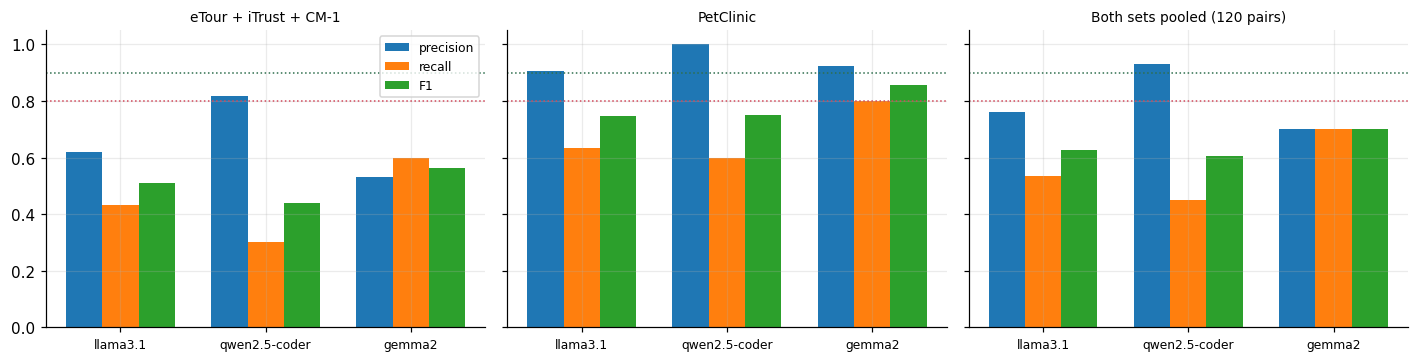

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (title, res) in zip(axes, list(per_set.items()) + [('Both sets pooled (120 pairs)', pooled_res)]):
    names_ = list(res); xx = np.arange(len(names_))
    for j, m_ in enumerate(('precision', 'recall', 'F1')): ax.bar(xx + (j - 1) * 0.25, [res[n][m_] for n in names_], 0.25, label=m_)
    ax.axhline(0.9, color=GREEN, ls=':', lw=1); ax.axhline(0.8, color=RED, ls=':', lw=1)      # the two targets: precision 0.9, recall 0.8
    ax.set_xticks(xx); ax.set_xticklabels(names_, fontsize=8); ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=9)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [9]:
RERUN_LLM = False        # True: ask the LLM server again for a few stored pairs and compare with the stored answers
N_SPOT = 6

def llm_server_up():
    import urllib.request
    from dotenv import load_dotenv
    load_dotenv(ROOT / '.env')
    base = os.getenv('LLM_BASE_URL')
    if not base: return False
    try:
        urllib.request.urlopen(base.rstrip('/') + '/models', timeout=3); return True
    except Exception:
        return False

def spot_check(model_key, n=N_SPOT):
    from agents.traceability_agent import prompts
    from shared.llm.client import LLMClient
    llm = LLMClient(model=model_key, system_prompt=prompts.SYSTEM_PROMPT, user_prompt_template=prompts.USER_PROMPT_TEMPLATE)
    arts, agree = {}, 0
    stored_rows = saved('llm_compare.json')['models'][model_key][:n]
    for r in stored_rows:
        if r['dataset'] not in arts:
            arts[r['dataset']] = {a['id']: Artifact(**a) for a in json.loads((ROOT / 'data' / 'processed' / r['dataset'] / 'artifacts.json').read_text(encoding='utf-8'))}
        try:
            now = llm.verify_link(arts[r['dataset']][r['source']], arts[r['dataset']][r['target']])['is_linked']
        except Exception:
            now = None
        agree += (now == r['linked'])
        print(f"  {r['source']:>10s} -> {r['target'][:34]:34s} label {r['label']}  stored {r['linked']}  now {now}")
    print(f'{agree} of {len(stored_rows)} answers agree with the stored ones')

if not RERUN_LLM:
    print('RERUN_LLM is False: the table above is computed from the stored answers only.')
elif not llm_server_up():
    print('RERUN_LLM is True but no LLM server answered at LLM_BASE_URL (see .env): nothing was re-asked.')
else:
    spot_check(next(iter(saved('llm_compare.json')['models'])))

RERUN_LLM is False: the table above is computed from the stored answers only.


**Observations**
* The models trade precision against recall. Qwen is the strictest (precision 0.93 but it finds only 45% of the true links), Gemma 2 is the most lenient (recall 0.70), Llama 3.1 sits between.
* **The order depends on the data.** Gemma 2's precision is 0.53 on eTour/iTrust/CM-1 and 0.92 on PetClinic. PetClinic is the easier set (short code, clear requirements, mostly obviously unrelated non-links), so its precision is optimistic.
* Pooled over the 120 pairs Gemma 2 has the best F1 (0.70 against 0.63 and 0.61) and the best recall, but it is the slowest (about 51 s per answer) and gave no usable answer for 5 pairs. The pooled intervals overlap strongly, so the differences are indicative only.
* **No model reaches both targets** (precision 0.90 and recall 0.80); links in the "Needs review" tier are checked by a person.

**Limits.** 60 pairs per set. The prompt, the confidence tiers and the decay results elsewhere in this notebook were measured with Llama 3.1; after switching the verifier they need to be measured again.

## 8. Verification prompt

**Objective.** The default *expert* prompt accepts anything plausible. The *evidence* prompt makes the model quote code that satisfies the requirement, and the program checks the quote against the code. Which gives better links?

**Procedure.** 36 PetClinic links that a reviewer marked correct or wrong (an AI reviewer, not a person). The counts are recomputed from the stored verdicts (`evidence_ab_spring-petclinic.json`). The second cell runs the quote check itself on a real file.

36 links judged by the reviewer: 21 correct, 15 wrong (4 more were marked unsure and are left out)
the expert prompt had accepted all of them

                    kept  correct kept  wrong kept  precision    95% interval
expert prompt         36            21          15      0.583    [0.42, 0.73]
evidence prompt       17            14           3      0.824    [0.59, 0.94]

correct links kept: 14 of 21   wrong links rejected: 12 of 15
matches the stored summary: True


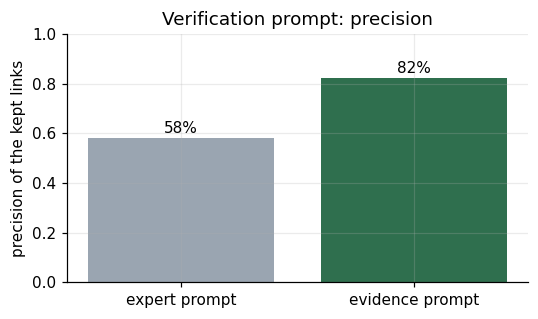

In [21]:
ev = saved('evidence_ab_spring-petclinic.json')
rows = [r for r in ev['rows'] if r['label'] in ('correct', 'wrong')]
n_correct = sum(r['label'] == 'correct' for r in rows); n_wrong = len(rows) - n_correct
kept = [r for r in rows if r['ev_linked']]
tp = sum(r['label'] == 'correct' for r in kept); fp = len(kept) - tp
std_p, ev_p = n_correct / len(rows), tp / len(kept)
print(f'{len(rows)} links judged by the reviewer: {n_correct} correct, {n_wrong} wrong (4 more were marked unsure and are left out)')
print('the expert prompt had accepted all of them')
print(f'\n{"":18s}{"kept":>6s}{"correct kept":>14s}{"wrong kept":>12s}{"precision":>11s}{"95% interval":>16s}')
lo, hi = wilson(n_correct, len(rows)); print(f'{"expert prompt":18s}{len(rows):6d}{n_correct:14d}{n_wrong:12d}{std_p:11.3f}{f"[{lo:.2f}, {hi:.2f}]":>16s}')
lo, hi = wilson(tp, len(kept));        print(f'{"evidence prompt":18s}{len(kept):6d}{tp:14d}{fp:12d}{ev_p:11.3f}{f"[{lo:.2f}, {hi:.2f}]":>16s}')
print(f'\ncorrect links kept: {tp} of {n_correct}   wrong links rejected: {n_wrong - fp} of {n_wrong}')
print('matches the stored summary:', (round(std_p, 3), round(ev_p, 3), f'{tp}/{n_correct}') == (ev['summary']['standard_precision'], ev['summary']['evidence_precision'], ev['summary']['correct_links_kept']))
fig, ax = plt.subplots(figsize=(5, 3)); ax.bar(['expert prompt', 'evidence prompt'], [std_p, ev_p], color=[GREY, GREEN])
for i, v in enumerate([std_p, ev_p]): ax.text(i, v + .02, f'{v:.0%}', ha='center')
ax.set_ylim(0, 1); ax.set_ylabel('precision of the kept links'); ax.set_title('Verification prompt: precision'); plt.tight_layout(); plt.show()

### The quote check, run on a real file

In [22]:
from shared.llm.client import parse_evidence_reply
pc = {a['id']: Artifact(**a) for a in json.loads((ROOT / 'data' / 'processed' / 'petclinic' / 'artifacts.json').read_text(encoding='utf-8'))}
sample = next(r for r in ev['rows'] if r['label'] == 'correct' and r['ev_linked'])
target_text = llm_text(pc[sample['code']])
real_quote = max((l.strip() for l in target_text.splitlines() if not l.strip().startswith(('import', 'package', '//', '*', '/*', '@'))), key=len)     # the longest code line of the file
cases = {'quote that is in the code': {'coverage': 'full', 'evidence': real_quote, 'reasoning': 'the method does this'},
         'quote that is not in the code': {'coverage': 'full', 'evidence': 'public void scheduleVisitWithReminder(Visit visit)', 'reasoning': 'the method does this'},
         'no quote at all': {'coverage': 'partial', 'evidence': '', 'reasoning': 'looks related'},
         'model says no': {'coverage': 'none', 'evidence': '', 'reasoning': 'unrelated'}}
print(f'code file: {sample["code"][-60:]}\n')
for name, reply in cases.items():
    out = parse_evidence_reply(reply, target_text)
    print(f'{name:30s} -> is_linked={out["is_linked"]!s:5s} confidence={out["confidence"]}')

code file: ingframework/samples/petclinic/system/WelcomeController.java

quote that is in the code      -> is_linked=True  confidence=0.9
quote that is not in the code  -> is_linked=False confidence=0.1
no quote at all                -> is_linked=False confidence=0.1
model says no                  -> is_linked=False confidence=0.1


**Observations**
* The evidence prompt keeps 17 of the 36 links and rejects 12 of the 15 wrong ones, raising precision from 58% to 82%; it also drops 7 of the 21 correct links.
* The two precision intervals overlap ([0.42, 0.73] and [0.59, 0.94]): with 36 links the gain is **suggestive, not established**.
* The quote check works as intended: a quote that is not in the code, or no quote, turns a "linked" answer into "not linked".

**Conclusion.** The prompt is a precision/recall trade-off, not a free win. On a later project (the BMI calculator) the evidence prompt rejected correct links, so the dashboard uses the expert prompt.

**Limits.** One project, 36 links, labels from an AI reviewer.

## 9. Decay detection

**Objective.** When the code or a requirement changes, how often is a broken link flagged? Edits are injected into verified links; harmless edits (a comment appended) serve as controls for false alarms.

**Detectors**
* **LLM alone:** re-asks the LLM whether the link still holds.
* **LLM + meaning-change check** (`semdiff.py`): when a link is verified, a fingerprint of the numbers, negations, `true`/`false` and comparison operators of both texts is saved (comments ignored). Later the fingerprint of the current text is compared; a difference flags the link with the exact change, without calling the LLM.

**Procedure.**
1. The meaning-change check is **run here, without any LLM**, on all 30 sampled ground-truth links and every edit of the harness (`decay_injection.py`).
2. The LLM outcomes come from the two stored runs (`decay_injection_v2.json` LLM alone, `decay_injection_v3.json` with the check); the rates and intervals are recomputed from their per-edit outcomes. Only 11 of the 30 links could be used there, because the LLM itself rejected the others before any edit.

In [23]:
from agents.traceability_agent.decay_injection import _gold_links, BREAKING_MUTATIONS, CONTROL_MUTATION, REQUIREMENT_BREAKING_MUTATIONS, REQUIREMENT_CONTROL, summarise_injection
from agents.traceability_agent.semdiff import fingerprint_pair, pair_changes

# the same 30 links the stored runs used: ground-truth links of iTrust, eTour and CM-1, 10 each, seed 7, texts of at most 3000 characters
arts, links = [], []
for ds in ('itrust', 'etour', 'cm1'):
    a, l = _gold_links(ds, 10, 7, 3000)
    arts += [x for x in a if x.id not in {y.id for y in arts}]; links += l
by_id = {a.id: a for a in arts}
target_muts = {**BREAKING_MUTATIONS, CONTROL_MUTATION[0]: CONTROL_MUTATION[1]}
req_muts = {**REQUIREMENT_BREAKING_MUTATIONS, REQUIREMENT_CONTROL[0]: REQUIREMENT_CONTROL[1]}

stats = {}
for link in links:
    src, tgt = by_id[link.source_id], by_id[link.target_id]
    stored = fingerprint_pair(src, tgt, llm_text(tgt))                   # what is saved when the link is verified
    for name, mutate in target_muts.items():
        text = mutate(tgt.text)
        if text != tgt.text:
            edited = tgt.model_copy(update={'text': text})
            s = stats.setdefault(name, [0, 0]); s[0] += 1; s[1] += bool(pair_changes(stored, src, edited, llm_text(edited)))
    for name, mutate in req_muts.items():
        text = mutate(src.text)
        if text != src.text:
            s = stats.setdefault(name, [0, 0]); s[0] += 1; s[1] += bool(pair_changes(stored, src.model_copy(update={'text': text}), tgt, llm_text(tgt)))
controls = {'cosmetic_control', 'requirement_cosmetic_control'}
print(f'meaning-change check alone (no LLM), {len(links)} links, every edit that changed the text:')
print(f"{'edit':32s}{'flagged':>9s}{'edits':>7s}")
for name, (n, f) in stats.items():
    print(f"{name + (' (harmless)' if name in controls else ''):32s}{f:9d}{n:7d}")
n_b = sum(n for k, (n, f) in stats.items() if k not in controls); f_b = sum(f for k, (n, f) in stats.items() if k not in controls)
n_c = sum(n for k, (n, f) in stats.items() if k in controls); f_c = sum(f for k, (n, f) in stats.items() if k in controls)
print(f'\nbreaking edits flagged: {f_b} of {n_b} ({f_b / n_b:.1%}, 95% interval {wilson(f_b, n_b)[0]:.0%} to {wilson(f_b, n_b)[1]:.0%});  harmless edits flagged: {f_c} of {n_c}')

meaning-change check alone (no LLM), 30 links, every edit that changed the text:
edit                              flagged  edits
unrelated_replacement                  19     30
strip_to_first_sentence                19     29
cosmetic_control (harmless)             0     30
requirement_unrelated                  17     30
requirement_cosmetic_control (harmless)        0     30
negate_behavior                         6      9
change_numbers                          8     15
requirement_negated                    11     11

breaking edits flagged: 80 of 124 (64.5%, 95% interval 56% to 72%);  harmless edits flagged: 0 of 60


### LLM alone against LLM + meaning-change check (recomputed from the stored per-edit outcomes)

                                    detected    rate    95% interval  false alarms
LLM alone                              35/46   76.1%      [62%, 86%]            0%
LLM + meaning-change check             44/46   95.7%      [86%, 99%]            0%

edits caught only with the meaning-change check: 9; caught only by the LLM alone: 0; sign test p = 0.0039


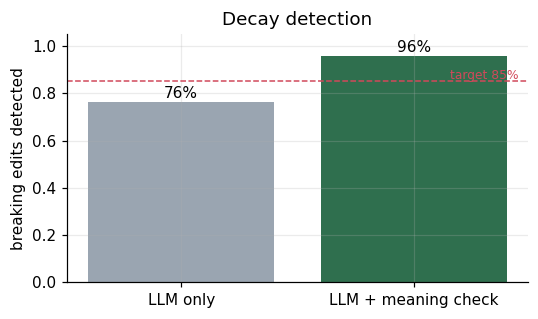

In [24]:
v2, v3 = saved('decay_injection_v2.json'), saved('decay_injection_v3.json')
r2, r3 = summarise_injection(v2['per_link']), summarise_injection(v3['per_link'])         # recomputed from the stored per-edit outcomes
print(f"{'':34s}{'detected':>10s}{'rate':>8s}{'95% interval':>16s}{'false alarms':>14s}")
for name, r in (('LLM alone', r2), ('LLM + meaning-change check', r3)):
    inj = sum(r['per_mutation'][m]['injected'] for m in list(BREAKING_MUTATIONS) + list(REQUIREMENT_BREAKING_MUTATIONS)); det = round(r['decay_detection_accuracy'] * inj)
    lo, hi = r['decay_detection_ci95']
    print(f"{name:34s}{f'{det}/{inj}':>10s}{r['decay_detection_accuracy']:8.1%}{f'[{lo:.0%}, {hi:.0%}]':>16s}{r['false_decay_rate']:14.0%}")
only3 = only2 = 0                                                    # same edits, paired: caught only by one of the two runs
for a_, b_ in zip(v2['per_link'], v3['per_link']):
    for m_, flag3 in b_['outcome'].items():
        if m_ in controls or flag3 is None or a_['outcome'].get(m_) is None: continue
        only3 += bool(flag3) and not a_['outcome'][m_]; only2 += bool(a_['outcome'][m_]) and not flag3
from scipy.stats import binomtest
p = binomtest(only3, only3 + only2, 0.5).pvalue if only3 + only2 else 1.0
print(f'\nedits caught only with the meaning-change check: {only3}; caught only by the LLM alone: {only2}; sign test p = {p:.4f}')
fig, ax = plt.subplots(figsize=(5, 3)); vals = [r2['decay_detection_accuracy'], r3['decay_detection_accuracy']]
ax.bar(['LLM only', 'LLM + meaning check'], vals, color=[GREY, GREEN])
for i, v in enumerate(vals): ax.text(i, v + .02, f'{v:.0%}', ha='center')
ax.axhline(0.85, color=RED, ls='--', lw=1); ax.text(1.45, 0.86, 'target 85%', color=RED, fontsize=8, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('breaking edits detected'); ax.set_title('Decay detection'); plt.tight_layout(); plt.show()

**Observations**
* The meaning-change check alone flags 80 of 124 breaking edits (65%) and none of 60 harmless ones. It catches what changes a number, a negation, a boolean or an operator and misses edits that leave those untouched, for example replacing a text by an unrelated one that contains none of them (19 of 30). That part is left to the LLM.
* On the same 46 edits, adding the check lifts detection from 35 to 44 (76% to 96%). Nine edits are caught only with the check and none only by the LLM alone (sign test p = 0.004); false alarms stay at 0 of 22.

**Conclusion.** The combination meets the 85% target; the two detectors cover different edits.

**Limits.** The check was designed around these kinds of edits, so the figure is favourable; real edits are more varied. Only 11 links were usable for the LLM runs, and 8 of the 11 are CM-1 design text.

## 10. Targets against measurements

Every row says where its number comes from.

In [25]:
from agents.traceability_agent.config import MAX_VERIFY_SECONDS
summary = saved('summary.json')
secs = [r['seconds'] for file in SETS.values() for rows in saved(file)['models'].values() for r in rows if r.get('seconds') is not None]
stage1_itrust = live['itrust']['MiniLM + TF-IDF'][10]
precision_stored = next(x for x in summary['prf'] if x['dataset'].startswith('iTrust') and 'Full pipeline' in x['method'])
rows = [
    ('Precision >= 90%',            f"{precision_stored['precision']:.1%}", 'stored (iTrust, 10 requirements, full pipeline)', precision_stored['precision'] >= 0.9),
    ('Recall >= 80%',               f'{stage1_itrust:.1%}',                 're-run above (iTrust, stage 1, top 10)',               stage1_itrust >= 0.8),
    ('Verification <= 5 s',         f'{np.mean(secs):.0f} s per answer',    'recomputed from stored answers (CPU-only server)',      np.mean(secs) <= MAX_VERIFY_SECONDS),
    ('Decay detection >= 85%',      f"{r3['decay_detection_accuracy']:.1%}", 'recomputed from stored per-edit outcomes',              r3['decay_detection_accuracy'] >= 0.85),
]
print(f"{'target':26s}{'measured':>20s}  {'met':5s}  source")
for t, m, s, ok in rows: print(f'{t:26s}{m:>20s}  {"yes" if ok else "no":5s}  {s}')

target                                measured  met    source
Precision >= 90%                         37.5%  no     stored (iTrust, 10 requirements, full pipeline)
Recall >= 80%                            41.9%  no     re-run above (iTrust, stage 1, top 10)
Verification <= 5 s            40 s per answer  no     recomputed from stored answers (CPU-only server)
Decay detection >= 85%                   95.7%  yes    recomputed from stored per-edit outcomes


**Notes.**
* The precision row is the stored 10-requirement iTrust sample. A larger sample in `docs/c4_reranker_and_stage1_analysis.md` (section 5.w, 82 requirements, expert prompt) gives precision 46%, recall 21%; both are far below 90% and 80%.
* The latency row is the mean over all stored pair-comparison answers of the three models on the CPU-only server (Llama and Qwen about 34 s, Gemma 2 about 51 s); `summary.json` records a typical 52 s and p95 80 s for the full pipeline. Either way the 5 s target is missed by an order of magnitude.
* Recall is limited first by stage 1: a true link outside the shortlist cannot be verified.

## 11. Decisions and open items

| Topic | Decision | Evidence |
|---|---|---|
| Stage-1 model | TF-IDF + MiniLM, fused by z-score | beats TF-IDF alone and MiniLM alone (intervals exclude 0); code-search hybrid is tied |
| Fine-tuned CodeBERT | not part of the main pipeline | no gain on average, small pooled loss; MiniLM cannot be replaced by it |
| Cross-encoder reranker | not part of the pipeline | gain only on the datasets where the weight was chosen; none on the other four |
| Query expansion | not used | no gain; 28% of the suggested names exist in the code |
| Verifier LLM | Gemma 2 has the best F1; Qwen the best precision; none meets the targets | 120 pairs, wide intervals |
| Verification prompt | expert prompt in the dashboard; evidence prompt is an option | precision up, recall down; 36 links, intervals overlap |
| Decay detection | LLM + meaning-change check | 76% to 96% on the same 46 edits (sign test p = 0.004) |

**Open items**
1. `.env.example` enables `c4-codebert` by default although section 4 shows no gain; decide whether to switch it off (`EXTRA_EMBEDDING_MODEL_NAMES=` empty) or to retrain it on real labelled links first.
2. Train and test CodeBERT on real labelled links with leave-one-project-out cross-validation (`codebert_cross_validation.ipynb`); no result file exists yet.
3. After the verifier LLM was switched, re-measure the prompt, the confidence tiers and the decay detection (all measured with Llama 3.1).
4. Test a larger stage-1 shortlist end to end (stage 1, LLM, precision and recall): the top 50 contains 81% of the true links, the top 10 only 41%, at about five times the LLM calls.
5. Label the PetClinic links by a person instead of an AI reviewer before relying on the prompt comparison.